# 가설검정: 자녀가 있는 외국인은 거주안정성·대출 상환능력이 높은가?

**H₀**: 자녀 보유(특히 자녀가 한국에 함께 거주)와 거주안정성·상환능력 지표는 무관하다.
**H₁**: 자녀(가족)와 함께 정착한 외국인일수록 거주안정성·상환능력이 높다.

| 개념 | 대리지표 | 방향 |
|---|---|---|
| 거주안정성 | 체류기간 10년 이상, 계속 체류 희망, 국적 취득 | ↑ 좋음 |
| 담보·자산 | 자기 집 거주 | ↑ 좋음 |
| 상환 여력 | 월소득 300만 원 이상(소득자 중), 저축 비중 | ↑ 좋음 |
| 연체 위험 | 공과금 기한 내 미납 경험 | ↓ 좋음 |

### 자료의 한계와 3단계 설계
공표된 「이민자체류실태및고용조사」 표에는 **자녀 유무 × 위 지표의 교차표가 없다** (자녀는 성별로만 공표).
따라서 개인 단위 검정은 MDIS 마이크로데이터가 필요하고, 지금은 실제 공표자료로 두 가지 **간접 검정**을 한다.

| 단계 | 단위 | 자료 | 방법 | 한계 |
|---|---|---|---|---|
| A1 집단 | 체류자격 8개 | 2025 이민자체류실태조사 통계표 | 가족정착형(F-4·F-5·F-6) vs 취업·학업형 비율차, 근사 z검정 | 체류자격 = 자녀의 대리변수 |
| A2 지역 | 시군구 229개 | 행안부 2024 외국인주민 현황 | 외국인주민 100명당 자녀 수 ↔ 10년+ 체류·국적취득 비중, Spearman·OLS(HC3) | 생태학적 오류 |
| B 개인 | 응답자 ~2만 명 | MDIS 공개용 원자료 | 카이제곱, 가중 로지스틱 회귀(조정 OR) | 원자료 신청 필요 |

**선행근거**: 이민정책연구원 통계브리프 2025-14(신한카드 외국인 가맹점 10,323곳) — 시군구 외국인 가맹점 수와
외국인주민자녀 수의 상관 0.817, 결혼이민자 0.920, 외국국적동포 0.922, 외국인근로자 0.565.
→ 가족 정착형 집단이 많은 지역에서 외국인 자영업이 활성화된다는 관측. 본 분석은 같은 논리를 *거주안정성·상환능력*으로 확장한다.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from src import load as L
from src import viz as V
from src import mdis_test as M

V.setup()
C, SERIES, BLUE = V.C, V.SERIES, V.BLUE
FIG = ROOT / "figures"; PROC = ROOT / "data" / "processed"
SRC_SURVEY = "국가데이터처·법무부 이민자체류실태및고용조사 보도자료 통계표"
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

---
## 0. 기초: 자녀를 둔 외국인은 얼마나 되고, 자녀는 어디에 사는가

      label    pop_k  with_children_k  all_in_korea_k  all_abroad_k
   2023 외국인 1,430.40           801.30          410.50        323.50
   2024 외국인 1,560.60           875.40          435.90        372.40
   2025 외국인 1,692.30           921.40          433.10        415.60
2025 외국인 남자   979.60           500.40          175.70        296.40
2025 외국인 여자   712.80           421.00          257.40        119.20


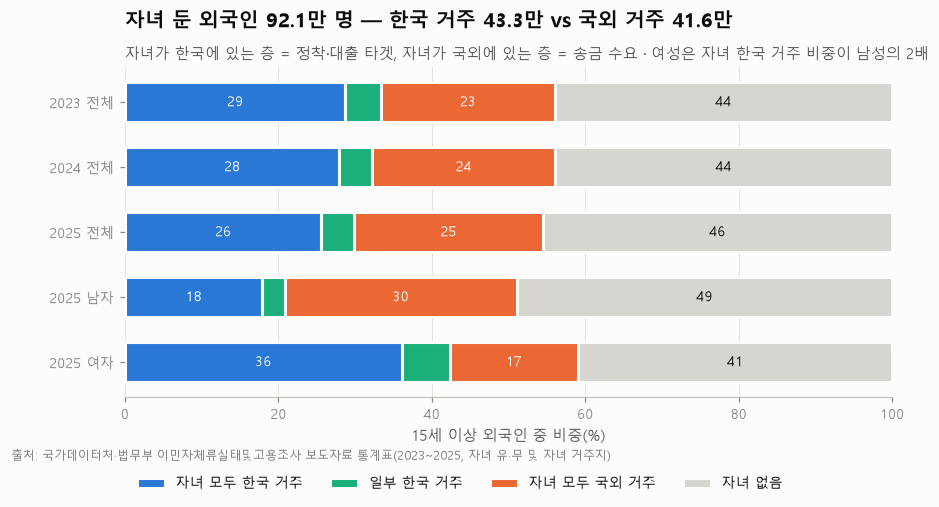

In [2]:
ch = L.load_children()
ch["label"] = ch.year.astype(str) + " " + ch.group
show = ch[ch.group.isin(["외국인", "외국인 남자", "외국인 여자"])].copy()
show = show[(show.group == "외국인") | (show.year == 2025)]
show = show[show.year >= 2023].sort_values(["year", "group"]).reset_index(drop=True)   # KOSIS는 2017년부터 있지만 그림은 최근 3년만
cats = [("all_in_korea_k", "자녀 모두 한국 거주", SERIES[0]), ("partly_korea_k", "일부 한국 거주", SERIES[2]),
        ("all_abroad_k", "자녀 모두 국외 거주", SERIES[1]), ("no_children_k", "자녀 없음", C["neutral"])]
pct = show[[c for c, _, _ in cats]].div(show.pop_k, axis=0) * 100
print(show[["label", "pop_k", "with_children_k", "all_in_korea_k", "all_abroad_k"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.9))
labels = [f"{r.year} {r.group.replace('외국인 ', '').replace('외국인', '전체')}" for r in show.itertuples()]
y = np.arange(len(show))[::-1]
left = np.zeros(len(show))
for (c, name, col) in cats:
    ax.barh(y, pct[c], left=left, color=col, height=0.62, label=name, edgecolor=C["surface"], linewidth=2)
    for yi, l, v in zip(y, left, pct[c]):
        if v >= 8:
            ax.text(l + v / 2, yi, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color="#ffffff" if col != C["neutral"] else C["ink"])
    left += pct[c].values
ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlim(0, 100); ax.set_xlabel("15세 이상 외국인 중 비중(%)")
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.2))
r25 = ch[(ch.year == 2025) & (ch.group == "외국인")].iloc[0]
ax.set_title(f"자녀 둔 외국인 {r25.with_children_k/10:.1f}만 명 — 한국 거주 {r25.all_in_korea_k/10:.1f}만 vs 국외 거주 {r25.all_abroad_k/10:.1f}만")
subtitle_txt = "자녀가 한국에 있는 층 = 정착·대출 타겟, 자녀가 국외에 있는 층 = 송금 수요 · 여성은 자녀 한국 거주 비중이 남성의 2배"
V.subtitle(ax, subtitle_txt)
V.finish(fig, FIG / "h01_children_status.png", f"{SRC_SURVEY}(2023~2025, 자녀 유·무 및 자녀 거주지)")

---
## A1. 집단 단위: 체류자격별 거주안정성·상환능력 (2025)
자녀를 동반·양육하며 정착하는 체류자격(**F-4 재외동포, F-5 영주, F-6 결혼이민**)과
가족 동반이 제한되거나 단기 목적인 체류자격(**E-9, H-2, E-1~7, 유학**)을 비교한다. (기타는 혼합 집단이라 제외)
공과금 미납률 = 경제적 어려움 경험률 × 공과금 미납 비중(경험자 중)으로 인구 대비 비율로 환산했다.

In [3]:
vz = L.load_survey_by_visa()
FAMILY, WORK = ["F4", "F5", "F6"], ["E9", "H2", "E1_7", "D2_D4"]
vz["grp"] = np.where(vz.visa.isin(FAMILY), "가족정착형", np.where(vz.visa.isin(WORK), "취업·학업형", "기타"))
IND = [  # 컬럼, 제목, 좋은 방향, 분모(인구 대비 'pop' / 소득자 'earn')
    ("stay_10yp", "체류 10년 이상(%)", +1, "pop"),
    ("wish_stay", "계속 체류 희망(%)", +1, "pop"),
    ("own_home", "자기 집 거주(%)", +1, "pop"),
    ("inc_300p_earn", "월소득 300만+ (소득자 중 %)", +1, "earn"),
    ("saving_share", "소득 중 저축 비중(%)", +1, None),
    ("utility_miss", "공과금 미납 경험(%) ↓좋음", -1, "pop"),
]
vz.to_csv(PROC / "visa_indicators_2025.csv", index=False)
vz[["visa_label", "pop_k"] + [c for c, *_ in IND]]

,visa_label,pop_k,stay_10yp,wish_stay,own_home,inc_300p_earn,saving_share,utility_miss
0,비전문취업(E-9),320.90,0.30,86.90,0.00,30.80,11.60,0.50
1,방문취업(H-2),73.00,45.80,94.50,5.75,40.88,18.60,4.66
2,전문인력(E-1~E-7),82.10,25.30,91.80,0.49,51.10,15.70,1.10
3,유학생(D-2·D-4),236.20,0.90,77.50,0.21,0.00,7.10,8.00
4,재외동포(F-4),409.80,60.00,95.70,20.16,45.95,18.40,3.91
5,영주(F-5),162.70,88.80,NaN,39.83,60.53,20.80,2.15
6,결혼이민(F-6),127.80,50.20,99.10,46.87,31.12,18.60,4.23
7,기타,279.90,14.80,88.60,9.29,27.96,14.80,5.01


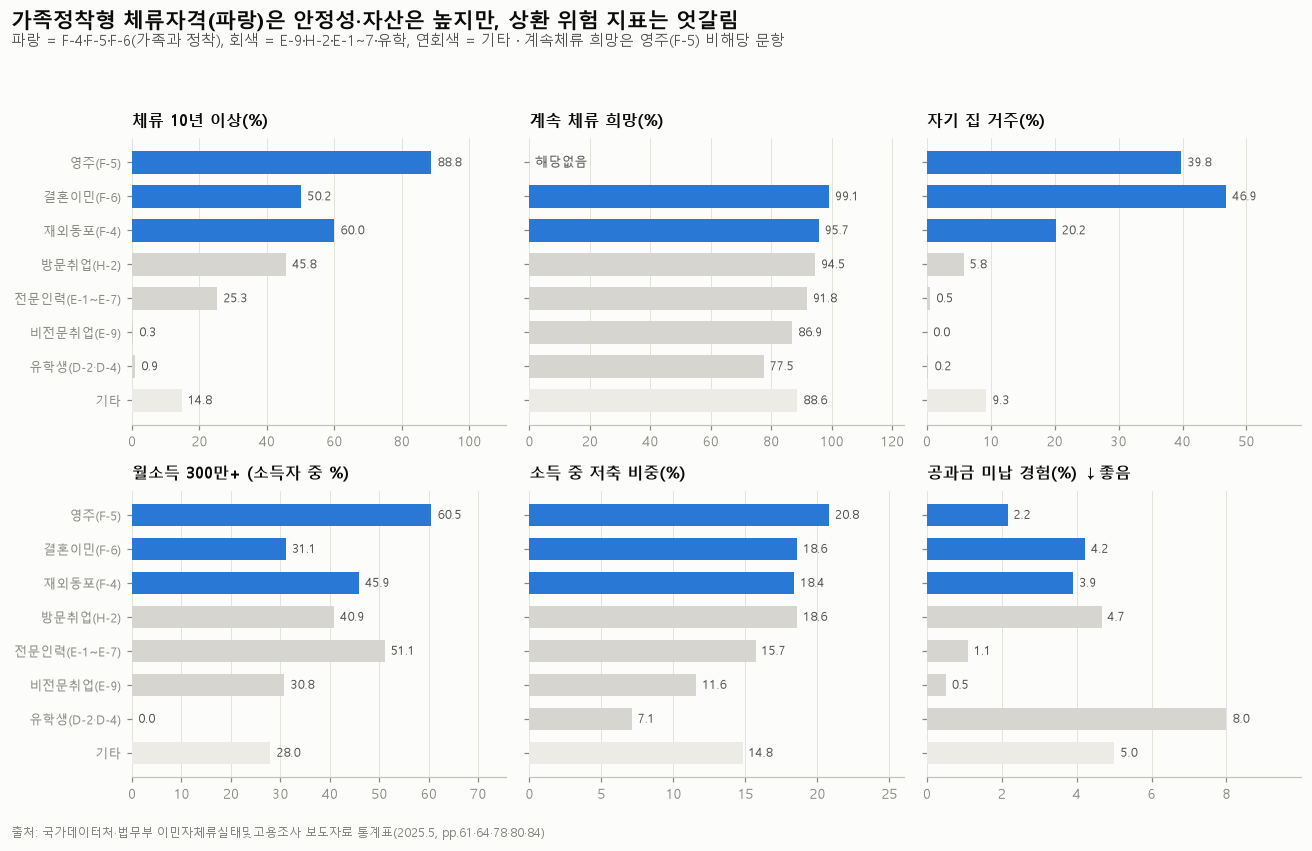

In [4]:
order = ["F5", "F6", "F4", "H2", "E1_7", "E9", "D2_D4", "ETC"]
v = vz.set_index("visa").loc[order]
col_of = lambda g: SERIES[0] if g == "가족정착형" else (C["neutral"] if g == "취업·학업형" else "#ecebe6")
fig, axes = plt.subplots(2, 3, figsize=(12, 7.2), sharey=True)
for ax, (c, title, good, _) in zip(axes.flat, IND):
    vals = v[c]
    ax.barh(range(len(v))[::-1], vals, color=[col_of(g) for g in v.grp], height=0.66)
    for i, val in zip(range(len(v))[::-1], vals):
        ax.text((0 if pd.isna(val) else val) + vals.max() * 0.02, i, "해당없음" if pd.isna(val) else f"{val:.1f}",
                va="center", fontsize=8.5, color=C["ink2"])
    ax.set_yticks(range(len(v))[::-1]); ax.set_yticklabels(v.visa_label, fontsize=8.5)
    ax.set_xlim(0, vals.max() * 1.25); ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
    ax.set_title(title, fontsize=10.5, pad=8)
fig.suptitle("가족정착형 체류자격(파랑)은 안정성·자산은 높지만, 상환 위험 지표는 엇갈림", x=0.01, ha="left",
             fontsize=14, fontweight="bold", y=1.02)
fig.text(0.01, 0.975, "파랑 = F-4·F-5·F-6(가족과 정착), 회색 = E-9·H-2·E-1~7·유학, 연회색 = 기타 · 계속체류 희망은 영주(F-5) 비해당 문항",
         fontsize=9.5, color=C["ink2"])
fig.tight_layout(rect=(0, 0, 1, 0.96))
V.finish(fig, FIG / "h02_visa_indicators.png", f"{SRC_SURVEY}(2025.5, pp.61·64·78·80·84)")

### A1 검정: 가족정착형 vs 취업·학업형 비율차
공표값은 가중 추정 인원(천 명)이라 그대로 검정하면 표본이 수십만으로 부풀어 p값이 무의미해진다.
그래서 **실제 표본(외국인 2만 명)을 인구 비중대로 배분한 유효표본(n_eff)**에 설계효과(DEFF) 2를 적용해
보수적으로 근사 검정하고, 해석은 **효과크기(비율차 %p, 비율비)** 중심으로 한다.

In [5]:
N_SAMPLE, DEFF, POP_TOTAL = 20000, 2.0, 1692.0

def pooled(sub, c, base):
    w = sub.pop_k * ((100 - sub.inc_none) / 100 if base == "earn" else 1.0)
    ok = sub[c].notna()
    w, p = w[ok], sub[c][ok] / 100
    return float((w * p).sum() / w.sum()), float(w.sum())

rows = []
for c, title, good, base in IND:
    if base is None:
        continue
    fa, fw = vz[vz.grp == "가족정착형"], vz[vz.grp == "취업·학업형"]
    p1, w1 = pooled(fa, c, base); p0, w0 = pooled(fw, c, base)
    n1, n0 = N_SAMPLE * w1 / POP_TOTAL / DEFF, N_SAMPLE * w0 / POP_TOTAL / DEFF
    diff = p1 - p0
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    pp = (p1 * n1 + p0 * n0) / (n1 + n0)
    z = diff / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n0))
    rows.append({"지표": title, "가족정착형(%)": p1 * 100, "취업·학업형(%)": p0 * 100, "차이(%p)": diff * 100,
                 "CI하한": (diff - 1.96 * se) * 100, "CI상한": (diff + 1.96 * se) * 100,
                 "비율비": p1 / p0 if p0 > 0 else np.nan, "z": z, "p": 2 * stats.norm.sf(abs(z)),
                 "n_eff(가족/취업)": f"{n1:,.0f}/{n0:,.0f}", "좋은방향": good,
                 "가설지지": (diff * good > 0) and (2 * stats.norm.sf(abs(z)) < 0.05)})
a1 = pd.DataFrame(rows)
a1.to_csv(PROC / "test_A1_visa_groups.csv", index=False)
a1

,지표,가족정착형(%),취업·학업형(%),차이(%p),CI하한,CI상한,비율비,z,p,n_eff(가족/취업),좋은방향,가설지지
0,체류 10년 이상(%),64.90,8.04,56.86,55.19,58.53,8.07,54.04,0.00,"4,139/4,209",1,True
1,계속 체류 희망(%),96.51,85.13,11.38,10.13,12.63,1.13,16.16,0.00,"3,177/4,209",1,True
2,자기 집 거주(%),29.60,0.72,28.89,27.47,30.30,41.34,36.92,0.00,"4,139/4,209",1,True
3,월소득 300만+ (소득자 중 %),47.41,30.42,16.99,14.56,19.41,1.56,13.58,0.00,"2,873/3,195",1,True
4,공과금 미납 경험(%) ↓좋음,3.56,3.48,0.08,-0.72,0.87,1.02,0.19,0.85,"4,139/4,209",-1,False


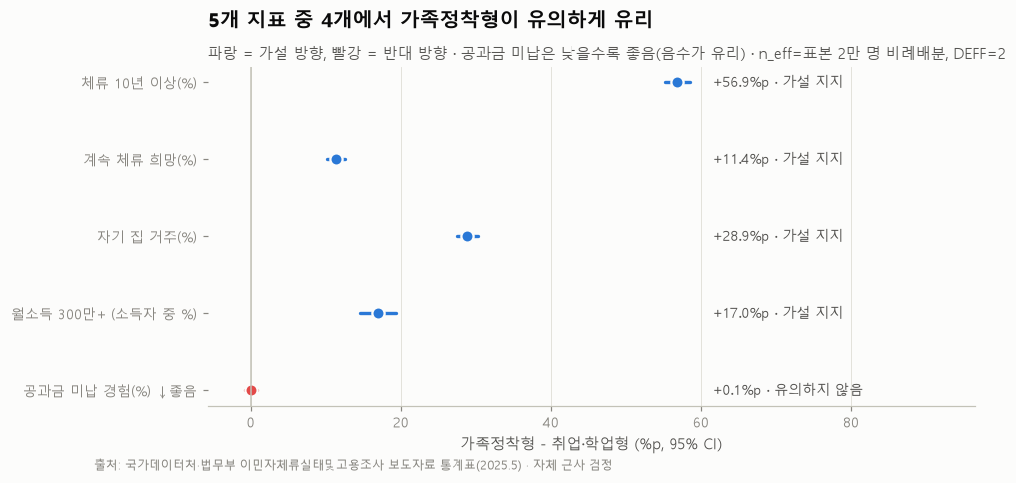

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
d = a1.iloc[::-1].reset_index(drop=True)
for i, r in d.iterrows():
    fav = r["차이(%p)"] * r["좋은방향"] > 0
    col = SERIES[0] if fav else SERIES[7]
    ax.plot([r.CI하한, r.CI상한], [i, i], color=col, linewidth=2.2, solid_capstyle="round")
    ax.plot(r["차이(%p)"], i, "o", color=col, markersize=8, markeredgecolor=C["surface"], markeredgewidth=1.5)
    tag = "가설 지지" if (fav and r.p < 0.05) else ("가설과 반대" if (not fav and r.p < 0.05) else "유의하지 않음")
    ax.text(max(d.CI상한) + 3, i, f"{r['차이(%p)']:+.1f}%p · {tag}", va="center", fontsize=9, color=C["ink2"])
ax.axvline(0, color=C["axis"], linewidth=1)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d["지표"])
ax.set_xlim(min(d.CI하한) - 5, max(d.CI상한) + 38); ax.set_xlabel("가족정착형 - 취업·학업형 (%p, 95% CI)")
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
nsup = int(a1["가설지지"].sum())
ax.set_title(f"5개 지표 중 {nsup}개에서 가족정착형이 유의하게 유리")
V.subtitle(ax, "파랑 = 가설 방향, 빨강 = 반대 방향 · 공과금 미납은 낮을수록 좋음(음수가 유리) · n_eff=표본 2만 명 비례배분, DEFF=2")
V.finish(fig, FIG / "h03_visa_effect_sizes.png", f"{SRC_SURVEY}(2025.5) · 자체 근사 검정")

---
## A2. 지역 단위: 외국인주민 자녀가 많은 시군구는 정착도가 높은가 (2024.11.1., 229개 시군구)
- **X (노출)**: 외국인주민 100명당 외국인주민자녀(출생, 미성년) 수
- **Y1 (거주안정성)**: 한국국적이 없는 외국인주민 중 **체류 10년 이상** 비중
- **Y2 (정착)**: 외국인주민 중 **한국국적 취득자** 비중
- **통제**: 외국인주민 규모(log), 외국인근로자 비중, 유학생 비중 (자녀가 적은 단기 체류 집단 구성효과)
- 결혼이민자 비중은 자녀와 거의 같은 경로(매개변수)라 기본 모형에서 빼고 민감도 모형에만 넣는다.

In [7]:
rg = L.load_mois_region()
rg = rg[rg.fr_total >= 1000].copy()        # 비율 안정성을 위해 외국인주민 1,000명 이상
rg["child_rate"] = rg.children / rg.fr_total * 100
rg["stay10"] = rg.stay_10y / rg.stay_known * 100
rg["natur"] = rg.naturalized / rg.fr_total * 100
# 사후(post-hoc) 보완 지표: 장기 정착자는 국적을 취득해 '비국적 10년+' 분모에서 빠지므로 둘을 합친 장기정착 비중
rg["settle_long"] = (rg.stay_10y + rg.naturalized) / (rg.stay_known + rg.naturalized) * 100
rg["log_fr"] = np.log10(rg.fr_total)
rg["worker_sh"] = rg.worker / rg.nonnat * 100
rg["student_sh"] = rg.student / rg.nonnat * 100
rg["marriage_sh"] = rg.marriage / rg.nonnat * 100
rg["label"] = rg["시도"].str[:2] + " " + rg["시군구"]
rg.to_csv(PROC / "region_children_settlement.csv", index=False)
print(f"분석 시군구 n={len(rg)} (외국인주민 1,000명 이상)")
sp = {y: stats.spearmanr(rg.child_rate, rg[y]) for y in ["stay10", "natur", "settle_long"]}
for y, r in sp.items():
    print(f"Spearman ρ(child_rate, {y}) = {r.statistic:.3f}, p = {r.pvalue:.2e}")
rg[["child_rate", "stay10", "natur", "worker_sh", "student_sh", "marriage_sh"]].describe().T[["mean", "50%", "min", "max"]]

분석 시군구 n=218 (외국인주민 1,000명 이상)
Spearman ρ(child_rate, stay10) = 0.044, p = 5.17e-01
Spearman ρ(child_rate, natur) = 0.654, p = 5.75e-28
Spearman ρ(child_rate, settle_long) = 0.398, p = 1.03e-09


,mean,50%,min,max
child_rate,15.85,15.43,3.36,32.07
stay10,16.67,14.22,6.21,36.21
natur,9.86,9.41,3.10,20.41
worker_sh,27.58,26.19,3.88,69.58
student_sh,12.93,7.18,0.14,58.27
marriage_sh,11.37,10.52,3.19,30.29


In [8]:
def fit(y, extra=""):
    z = rg[["child_rate", "log_fr", "worker_sh", "student_sh", "marriage_sh", y]].dropna()
    z = z.apply(lambda s: (s - s.mean()) / s.std())  # 통제변수에 비공개('*') 값이 있는 시군구는 제외
    f = f"{y} ~ child_rate + log_fr + worker_sh + student_sh{extra}"
    return smf.ols(f, data=z).fit(cov_type="HC3")

models = {("stay10", "기본"): fit("stay10"), ("stay10", "+결혼이민 비중"): fit("stay10", " + marriage_sh"),
          ("natur", "기본"): fit("natur"), ("natur", "+결혼이민 비중"): fit("natur", " + marriage_sh"),
          ("settle_long", "기본(사후)"): fit("settle_long")}
print("child_rate–marriage_sh 상관:", round(rg[["child_rate", "marriage_sh"]].corr().iloc[0, 1], 2),
      "→ '+결혼이민 비중' 모형은 다중공선성이 커서 계수 해석에 주의")
coef = pd.DataFrame([{"Y": y, "모형": m, "β(표준화)": r.params["child_rate"],
                      "lo": r.conf_int().loc["child_rate", 0], "hi": r.conf_int().loc["child_rate", 1],
                      "p": r.pvalues["child_rate"], "R²": r.rsquared, "n": int(r.nobs)}
                     for (y, m), r in models.items()])
coef.to_csv(PROC / "test_A2_region_ols.csv", index=False)
print(models[("stay10", "기본")].summary().tables[1])
coef

child_rate–marriage_sh 상관: 0.74 → '+결혼이민 비중' 모형은 다중공선성이 커서 계수 해석에 주의
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.735e-17      0.047  -3.66e-16      1.000      -0.093       0.093
child_rate    -0.0304      0.061     -0.495      0.621      -0.151       0.090
log_fr         0.1216      0.071      1.709      0.087      -0.018       0.261
worker_sh     -0.8462      0.077    -11.014      0.000      -0.997      -0.696
student_sh    -0.7808      0.069    -11.397      0.000      -0.915      -0.647


,Y,모형,β(표준화),lo,hi,p,R²,n
0,stay10,기본,-0.03,-0.15,0.09,0.62,0.62,178
1,stay10,+결혼이민 비중,-0.87,-1.03,-0.71,0.00,0.84,178
2,natur,기본,0.50,0.38,0.63,0.00,0.66,178
3,natur,+결혼이민 비중,0.25,0.05,0.45,0.01,0.68,178
4,settle_long,기본(사후),0.26,0.15,0.37,0.00,0.70,178


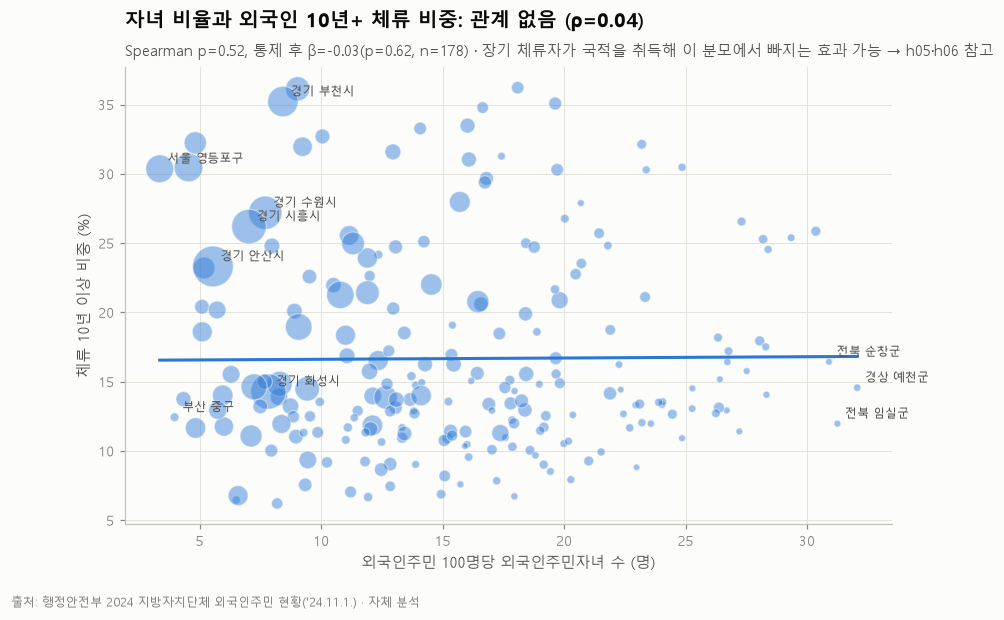

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.4))
sz = (rg.fr_total / rg.fr_total.max()) * 700 + 12
ax.scatter(rg.child_rate, rg.stay10, s=sz, color=SERIES[0], alpha=0.45, edgecolor=C["surface"], linewidth=0.8)
b = np.polyfit(rg.child_rate, rg.stay10, 1); xx = np.linspace(rg.child_rate.min(), rg.child_rate.max(), 50)
ax.plot(xx, np.polyval(b, xx), color=SERIES[0], linewidth=2)
for _, r in pd.concat([rg.nlargest(5, "fr_total"), rg.nlargest(3, "child_rate"), rg.nsmallest(2, "child_rate")]).drop_duplicates("label").iterrows():
    ax.annotate(r.label, (r.child_rate, r.stay10), xytext=(5, 4), textcoords="offset points", fontsize=8, color=C["ink2"])
ax.set_xlabel("외국인주민 100명당 외국인주민자녀 수 (명)"); ax.set_ylabel("체류 10년 이상 비중 (%)")
rho = sp["stay10"]
bb = coef[(coef.Y == "stay10") & (coef.모형 == "기본")].iloc[0]
sig = rho.pvalue < 0.05
ax.set_title(f"자녀 비율과 외국인 10년+ 체류 비중: {'유의한 관계' if sig else '관계 없음'} (ρ={rho.statistic:.2f})")
V.subtitle(ax, f"Spearman p={rho.pvalue:.2f}, 통제 후 β={bb['β(표준화)']:.2f}(p={bb.p:.2f}, n={bb.n}) · 장기 체류자가 국적을 취득해 이 분모에서 빠지는 효과 가능 → h05·h06 참고")
V.finish(fig, FIG / "h04_region_children_stay10.png", "행정안전부 2024 지방자치단체 외국인주민 현황('24.11.1.) · 자체 분석")

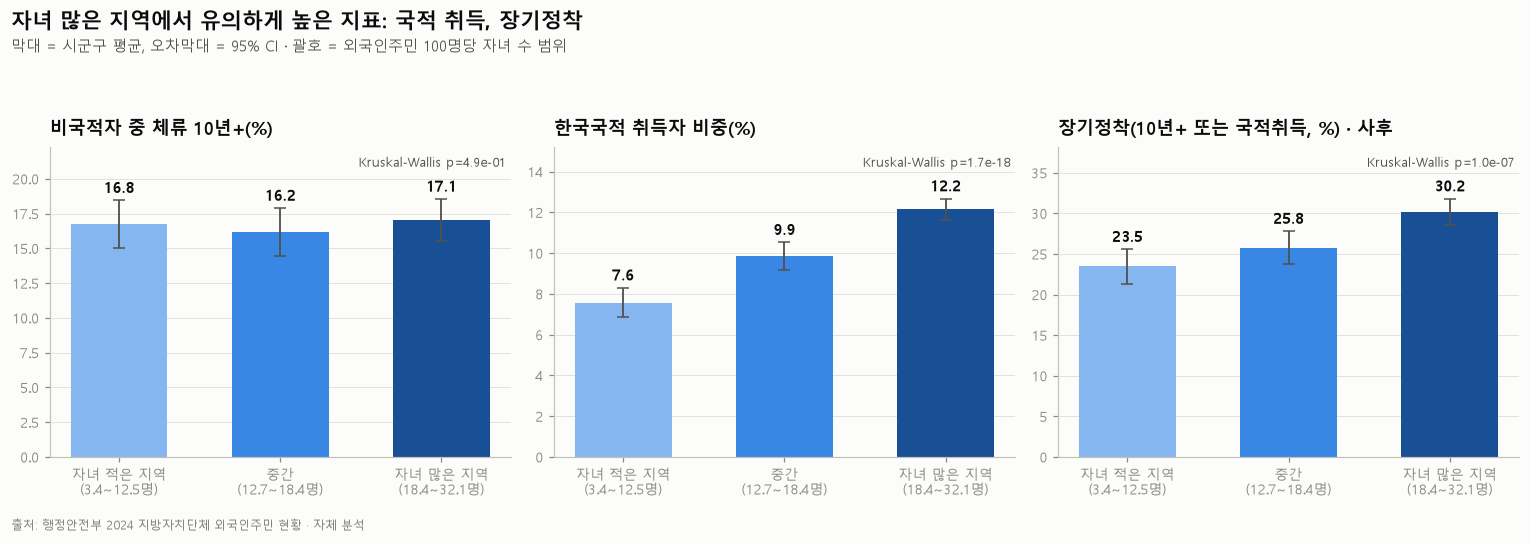

In [10]:
rg["tercile"] = pd.qcut(rg.child_rate, 3, labels=["자녀 적은 지역", "중간", "자녀 많은 지역"])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
kw_res = {}
for ax, (y, title) in zip(axes, [("stay10", "비국적자 중 체류 10년+(%)"), ("natur", "한국국적 취득자 비중(%)"),
                                 ("settle_long", "장기정착(10년+ 또는 국적취득, %) · 사후")]):
    g = rg.groupby("tercile", observed=True)[y]
    m, se = g.mean(), g.sem()
    ax.bar(range(3), m, color=[BLUE[3], BLUE[6], BLUE[10]], width=0.6, yerr=1.96 * se,
           error_kw=dict(ecolor=C["ink2"], elinewidth=1.2, capsize=4))
    for i, val in enumerate(m):
        ax.text(i, val + 1.96 * se.iloc[i] + m.max() * 0.03, f"{val:.1f}", ha="center", fontsize=10, fontweight="bold")
    kw = stats.kruskal(*[rg.loc[rg.tercile == t, y] for t in m.index]); kw_res[y] = (kw.pvalue, m.iloc[-1] - m.iloc[0])
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{t}\n({rg.loc[rg.tercile==t,'child_rate'].min():.1f}~{rg.loc[rg.tercile==t,'child_rate'].max():.1f}명)" for t in m.index], fontsize=9)
    ax.set_ylim(0, (m + 1.96 * se).max() * 1.2); ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=11.5, pad=8)
    ax.text(0.99, 0.97, f"Kruskal-Wallis p={kw.pvalue:.1e}", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=C["ink2"])
up = [t for y, t in [("stay10", "10년+ 체류"), ("natur", "국적 취득"), ("settle_long", "장기정착")] if kw_res[y][0] < 0.05 and kw_res[y][1] > 0]
fig.suptitle(f"자녀 많은 지역에서 유의하게 높은 지표: {', '.join(up) if up else '없음'}", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.04)
fig.text(0.01, 0.955, "막대 = 시군구 평균, 오차막대 = 95% CI · 괄호 = 외국인주민 100명당 자녀 수 범위", fontsize=9.5, color=C["ink2"])
fig.tight_layout(rect=(0, 0, 1, 0.93))
V.finish(fig, FIG / "h05_region_terciles.png", "행정안전부 2024 지방자치단체 외국인주민 현황 · 자체 분석")

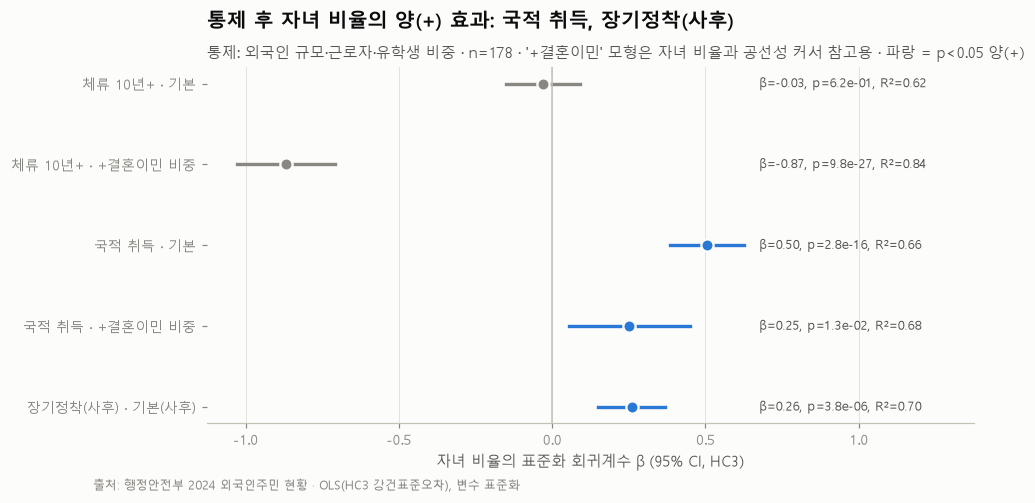

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
d = coef.iloc[::-1].reset_index(drop=True)
YN = {"stay10": "체류 10년+", "natur": "국적 취득", "settle_long": "장기정착(사후)"}
for i, r in d.iterrows():
    col = SERIES[0] if r.p < 0.05 and r["β(표준화)"] > 0 else C["muted"]
    ax.plot([r.lo, r.hi], [i, i], color=col, linewidth=2.2)
    ax.plot(r["β(표준화)"], i, "o", color=col, markersize=8, markeredgecolor=C["surface"], markeredgewidth=1.5)
    ax.text(d.hi.max() + 0.05, i, f"β={r['β(표준화)']:.2f}, p={r.p:.1e}, R²={r['R²']:.2f}", va="center", fontsize=8.5, color=C["ink2"])
ax.axvline(0, color=C["axis"], linewidth=1)
ax.set_yticks(range(len(d))); ax.set_yticklabels([f"{YN[r.Y]} · {r.모형}" for r in d.itertuples()])
ax.set_xlim(min(-0.1, d.lo.min() - 0.1), d.hi.max() + 0.75); ax.set_xlabel("자녀 비율의 표준화 회귀계수 β (95% CI, HC3)")
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
base = coef[coef["모형"].str.startswith("기본")]
pos = [YN[y] for y, b, p in zip(base.Y, base["β(표준화)"], base.p) if p < 0.05 and b > 0]
ax.set_title(f"통제 후 자녀 비율의 양(+) 효과: {', '.join(pos) if pos else '없음'}")
V.subtitle(ax, f"통제: 외국인 규모·근로자·유학생 비중 · n={int(coef.n.iloc[0])} · '+결혼이민' 모형은 자녀 비율과 공선성 커서 참고용 · 파랑 = p<0.05 양(+)")
V.finish(fig, FIG / "h06_region_ols_coef.png", "행정안전부 2024 외국인주민 현황 · OLS(HC3 강건표준오차), 변수 표준화")

미매칭: []


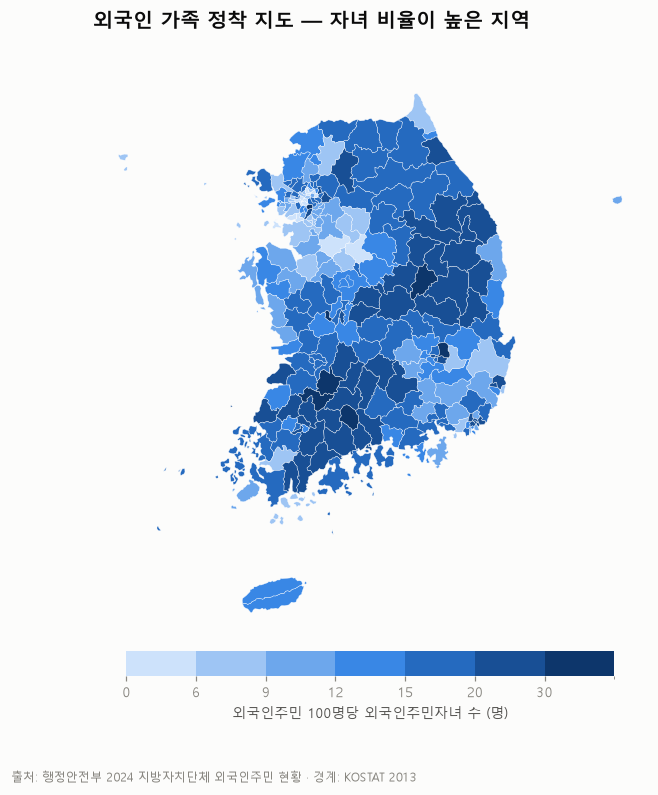

In [12]:
# 지도: 외국인주민 100명당 자녀 수 (geo 키에 맞춰 합산)
full = L.load_mois_region().copy()
inch = {"미추홀구": "남구", "중구": "중구·동구", "동구": "중구·동구"}
full["city"] = full["시군구"].map(L._city_key)
full.loc[full["시도"] == "인천광역시", "city"] = full.loc[full["시도"] == "인천광역시", "city"].replace(inch)
full.loc[full["시군구"] == "세종시", "city"] = "세종특별자치시"
geo_df = full.groupby(["시도", "city"], as_index=False)[["children", "fr_total"]].sum()
geo_df["child_rate"] = geo_df.children / geo_df.fr_total * 100
feats = L.load_geo_features(); fmap, unmatched = L.match_geo(geo_df, feats)
print("미매칭:", unmatched)
bins = [0, 6, 9, 12, 15, 20, 30, max(31, int(geo_df.child_rate.max()) + 1)]
cmap = ListedColormap([BLUE[i] for i in (0, 2, 4, 6, 8, 10, 12)]); norm = BoundaryNorm(bins, cmap.N)
fig, ax = plt.subplots(figsize=(6.5, 7.2))
V.draw_map(ax, feats, fmap, geo_df.child_rate.to_dict(), cmap, norm)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal", fraction=0.04, pad=0.02, ticks=bins[:-1])
cb.outline.set_visible(False); cb.set_label("외국인주민 100명당 외국인주민자녀 수 (명)", fontsize=9)
ax.set_title("외국인 가족 정착 지도 — 자녀 비율이 높은 지역", fontsize=13)
V.finish(fig, FIG / "h07_region_children_map.png", "행정안전부 2024 지방자치단체 외국인주민 현황 · 경계: KOSTAT 2013")

---
## B. 개인 단위 본검정 (MDIS 원자료)
MDIS 공개용 마이크로데이터를 `data/raw/mdis/`에 넣고 `src/mdis_test.py`의 `COLUMN_MAP`·`CODE_MAP`을 코드북대로 채우면
아래 셀이 **자녀 유무 / 자녀 한국 거주 여부 × 5개 지표**의 가중 비율차·카이제곱과
**성·연령·학력·체류자격·지역을 통제한 가중 로지스틱 회귀(조정 오즈비)**를 계산하고 그림 h08·h09를 만든다.

In [13]:
res = M.run()
if res is not None:
    display(res["biv_child"]); display(res["or_child"]); display(res["or_child_kr"])
    for key, fname, ttl in [("or_child", "h08_mdis_or_child.png", "자녀 있음"), ("or_child_kr", "h09_mdis_or_child_kr.png", "자녀 한국 거주")]:
        d = res[key].iloc[::-1].reset_index(drop=True)
        fig, ax = plt.subplots(figsize=(8.5, 3.6))
        for i, r in d.iterrows():
            good = M.OUTCOMES[[k for k, v in M.OUTCOMES.items() if v[0] == r["결과"]][0]][1]
            fav = (r.OR - 1) * good > 0
            col = SERIES[0] if (fav and r.p < 0.05) else (SERIES[7] if r.p < 0.05 else C["muted"])
            ax.plot([r.lo, r.hi], [i, i], color=col, linewidth=2.2); ax.plot(r.OR, i, "o", color=col, markersize=8)
            ax.text(d.hi.max() * 1.05, i, f"OR={r.OR:.2f} (p={r.p:.1e})", va="center", fontsize=8.5, color=C["ink2"])
        ax.axvline(1, color=C["axis"]); ax.set_xscale("log")
        ax.set_yticks(range(len(d))); ax.set_yticklabels(d["결과"]); ax.grid(axis="y", visible=False)
        ax.set_title(f"[개인 단위] {ttl} 외국인의 조정 오즈비")
        V.subtitle(ax, "통제: 성·연령·연령²·학력·체류자격·지역 · 가중 로지스틱 회귀 · 파랑 = 가설 방향 유의")
        V.finish(fig, FIG / fname, "MDIS 이민자체류실태및고용조사 2025 공개용 마이크로데이터 · 자체 분석")

[Part B 건너뜀] MDIS 파일 없음: C:\Users\ssw75\Desktop\대학\F1\data\raw\mdis 에 마이크로데이터를 저장하세요.
→ MDIS 공개용 마이크로데이터를 받으면 이 셀이 개인 단위 카이제곱·가중 로지스틱 회귀를 자동 실행합니다.


---
## 결론 요약 (Part A 결과 기반)

In [14]:
summary = pd.DataFrame([
    {"검정": "A2 지역: 자녀 비율 ↔ 체류 10년+", "결과": f"ρ={sp['stay10'].statistic:.2f}, 통제 β={coef.iloc[0]['β(표준화)']:.2f} (p={coef.iloc[0].p:.1e})",
     "판정": "지지" if coef.iloc[0].p < 0.05 and coef.iloc[0]['β(표준화)'] > 0 else "불충분"},
    {"검정": "A2 지역: 자녀 비율 ↔ 국적 취득", "결과": f"ρ={sp['natur'].statistic:.2f}, 통제 β={coef.iloc[2]['β(표준화)']:.2f} (p={coef.iloc[2].p:.1e})",
     "판정": "지지" if coef.iloc[2].p < 0.05 and coef.iloc[2]['β(표준화)'] > 0 else "불충분"},
] + [{"검정": f"A1 체류자격: {r['지표']}", "결과": f"{r['차이(%p)']:+.1f}%p (p={r.p:.1e})",
      "판정": "지지" if r["가설지지"] else ("반대" if r.p < 0.05 else "불충분")} for _, r in a1.iterrows()]
 + [{"검정": "B 개인 단위(MDIS)", "결과": "원자료 대기" if res is None else "위 표 참조", "판정": "—"}])
summary.to_csv(PROC / "hypothesis_summary.csv", index=False)
summary

,검정,결과,판정
0,A2 지역: 자녀 비율 ↔ 체류 10년+,"ρ=0.04, 통제 β=-0.03 (p=6.2e-01)",불충분
1,A2 지역: 자녀 비율 ↔ 국적 취득,"ρ=0.65, 통제 β=0.50 (p=2.8e-16)",지지
2,A1 체류자격: 체류 10년 이상(%),+56.9%p (p=0.0e+00),지지
3,A1 체류자격: 계속 체류 희망(%),+11.4%p (p=9.7e-59),지지
4,A1 체류자격: 자기 집 거주(%),+28.9%p (p=2.4e-298),지지
5,A1 체류자격: 월소득 300만+ (소득자 중 %),+17.0%p (p=5.1e-42),지지
6,A1 체류자격: 공과금 미납 경험(%) ↓좋음,+0.1%p (p=8.5e-01),불충분
7,B 개인 단위(MDIS),원자료 대기,—
